In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import gc

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [46]:
# Charger le dataset
df = pd.read_parquet("../data/processed/ml_dataset.parquet")
print("Dataset shape:", df.shape)
print("Colonnes:", df.columns.tolist())

# Créer la colonne label
df['label'] = df['is_error'].astype(int)

# Features numériques (sans 'message' qui est vide)
feature_cols = ['hour', 'day', 'month', 'weekday', 'message_length']
X = df[feature_cols].values
y = df['label'].values

print(f"\n✅ Features: {len(feature_cols)} dimensions")
print(f"✅ Target: {len(y):,} échantillons")
print(f"📊 Taux d'erreur: {y.mean():.4%}")

# Nettoyage mémoire
del df
gc.collect()

Dataset shape: (7224549, 13)
Colonnes: ['hour', 'day', 'month', 'weekday', 'is_weekend', 'message_length', 'is_error', 'is_warning', 'platform', 'event_type', 'source_file', 'log_id', 'message']

✅ Features: 5 dimensions
✅ Target: 7,224,549 échantillons
📊 Taux d'erreur: 6.8524%


1017

In [47]:
print("🚀 Création de features avancées...")

def create_advanced_features(df_chunk):
    """Crée des features avancées pour la détection d'anomalies"""
    
    # Features temporelles cycliques
    hour_sin = np.sin(2 * np.pi * df_chunk[:, 0] / 24)
    hour_cos = np.cos(2 * np.pi * df_chunk[:, 0] / 24)
    day_sin = np.sin(2 * np.pi * (df_chunk[:, 1] - 1) / 31)
    month_sin = np.sin(2 * np.pi * (df_chunk[:, 2] - 1) / 12)
    
    # Ratios et interactions
    hour_day_ratio = df_chunk[:, 0] / (df_chunk[:, 1] + 1)
    message_density = df_chunk[:, 4] / (df_chunk[:, 0] + 1)
    
    # Agrégation
    X_advanced = np.column_stack([
        df_chunk,  # features originales
        hour_sin, hour_cos, day_sin, month_sin,
        hour_day_ratio, message_density
    ])
    
    return X_advanced

# Appliquer sur tous les logs
X_advanced = create_advanced_features(X)
print(f"✅ Features avancées: {X_advanced.shape[1]} dimensions")
print(f"📊 Mémoire: {X_advanced.nbytes / 1e9:.2f} GB")

# Standardisation (important pour SVM et LOF)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_advanced)
print("✅ Features standardisées")

🚀 Création de features avancées...
✅ Features avancées: 11 dimensions
📊 Mémoire: 0.64 GB
✅ Features standardisées


In [48]:
# Pour éviter les MemoryError, on prend un échantillon représentatif
sample_size = 500000  # 500k logs pour l'analyse comparative
print(f"📊 Échantillonnage de {sample_size:,} logs...")

X_sample, _, y_sample, _ = train_test_split(
    X_scaled, y,
    train_size=sample_size,
    stratify=y,
    random_state=42
)

# Split final train/test
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.3,
    stratify=y_sample,
    random_state=42
)

print(f"\n📊 Train: {len(X_train):,} logs")
print(f"📊 Test: {len(X_test):,} logs")
print(f"📈 Taux d'erreur - Train: {y_train.mean():.4%}")
print(f"📈 Taux d'erreur - Test: {y_test.mean():.4%}")

📊 Échantillonnage de 500,000 logs...

📊 Train: 350,000 logs
📊 Test: 150,000 logs
📈 Taux d'erreur - Train: 6.8523%
📈 Taux d'erreur - Test: 6.8527%


In [49]:
error_rate = y_train.mean()

models = {
    "IsolationForest": IsolationForest(
        contamination=error_rate,
        random_state=42,
        n_estimators=200,
        max_samples=256,
        bootstrap=False,
        n_jobs=-1
    ),
    "OneClassSVM": OneClassSVM(
        kernel='rbf',
        gamma='scale',
        nu=error_rate,
        tol=0.001,
        cache_size=1000
    ),
    "LOF": LocalOutlierFactor(
        novelty=True,
        contamination=error_rate,
        n_neighbors=35,
        algorithm='ball_tree',
        leaf_size=30,
        metric='minkowski',
        n_jobs=-1
    )
}

print("🚀 Modèles configurés:")
for name in models.keys():
    print(f"  • {name} (contamination={error_rate:.4%})")

🚀 Modèles configurés:
  • IsolationForest (contamination=6.8523%)
  • OneClassSVM (contamination=6.8523%)
  • LOF (contamination=6.8523%)


In [50]:
results = []
conf_matrices = {}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"🔍 Entraînement {name}...")
    start_time = time.time()
    
    try:
        # Entraînement
        model.fit(X_train)
        train_time = time.time() - start_time
        print(f"  ⏱️ Temps: {train_time:.2f}s")
        
        # Prédiction
        preds = model.predict(X_test)
        preds = (preds == -1).astype(int)
        
        # Métriques
        precision = precision_score(y_test, preds)
        recall = recall_score(y_test, preds)
        f1 = f1_score(y_test, preds)
        cm = confusion_matrix(y_test, preds)
        
        results.append({
            "model": name,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "train_time": train_time
        })
        conf_matrices[name] = cm
        
        print(f"  ✓ Précision: {precision:.4f} ({precision*100:.2f}%)")
        print(f"  ✓ Rappel: {recall:.4f} ({recall*100:.2f}%)")
        print(f"  ✓ F1-score: {f1:.4f}")
        print(f"  ✓ Matrice de confusion:")
        print(f"     TN: {cm[0,0]:,} | FP: {cm[0,1]:,}")
        print(f"     FN: {cm[1,0]:,} | TP: {cm[1,1]:,}")
        
    except Exception as e:
        print(f"  ❌ Erreur: {e}")
        continue
    
    # Nettoyage mémoire
    gc.collect()


🔍 Entraînement IsolationForest...
  ⏱️ Temps: 5.81s
  ✓ Précision: 0.0198 (1.98%)
  ✓ Rappel: 0.0198 (1.98%)
  ✓ F1-score: 0.0198
  ✓ Matrice de confusion:
     TN: 129,599 | FP: 10,122
     FN: 10,075 | TP: 204

🔍 Entraînement OneClassSVM...
  ⏱️ Temps: 3089.76s
  ✓ Précision: 0.0484 (4.84%)
  ✓ Rappel: 0.0488 (4.88%)
  ✓ F1-score: 0.0486
  ✓ Matrice de confusion:
     TN: 129,859 | FP: 9,862
     FN: 9,777 | TP: 502

🔍 Entraînement LOF...
  ⏱️ Temps: 304.77s
  ✓ Précision: 0.1690 (16.90%)
  ✓ Rappel: 0.1705 (17.05%)
  ✓ F1-score: 0.1698
  ✓ Matrice de confusion:
     TN: 131,103 | FP: 8,618
     FN: 8,526 | TP: 1,753


In [51]:
# DataFrame des résultats
results_df = pd.DataFrame(results)
print("\n📊 RÉSULTATS DE LA COMPARAISON")
print("="*60)
print(results_df.to_string(index=False))

# Meilleur modèle
best_f1 = results_df.loc[results_df['f1'].idxmax()]
print(f"\n🏆 Meilleur modèle (F1): {best_f1['model']}")
print(f"   F1: {best_f1['f1']:.4f}")
print(f"   Précision: {best_f1['precision']:.4f}")
print(f"   Rappel: {best_f1['recall']:.4f}")

# Analyse des résultats
print("\n📈 ANALYSE DÉTAILLÉE")
print("="*60)
for _, row in results_df.iterrows():
    print(f"\n{row['model']}:")
    print(f"  • Précision: {row['precision']:.4f} → {row['precision']*100:.1f}% des détections sont correctes")
    print(f"  • Rappel: {row['recall']:.4f} → {row['recall']*100:.1f}% des erreurs sont détectées")
    
    if row['precision'] > row['recall']:
        print("  ⚠ Modèle prudent: peu de faux positifs mais manque des erreurs")
    else:
        print("  ⚠ Modèle sensible: détecte beaucoup d'erreurs mais avec des faux positifs")


📊 RÉSULTATS DE LA COMPARAISON
          model  precision   recall       f1  train_time
IsolationForest   0.019756 0.019846 0.019801    5.806644
    OneClassSVM   0.048437 0.048837 0.048636 3089.757054
            LOF   0.169029 0.170542 0.169782  304.766829

🏆 Meilleur modèle (F1): LOF
   F1: 0.1698
   Précision: 0.1690
   Rappel: 0.1705

📈 ANALYSE DÉTAILLÉE

IsolationForest:
  • Précision: 0.0198 → 2.0% des détections sont correctes
  • Rappel: 0.0198 → 2.0% des erreurs sont détectées
  ⚠ Modèle sensible: détecte beaucoup d'erreurs mais avec des faux positifs

OneClassSVM:
  • Précision: 0.0484 → 4.8% des détections sont correctes
  • Rappel: 0.0488 → 4.9% des erreurs sont détectées
  ⚠ Modèle sensible: détecte beaucoup d'erreurs mais avec des faux positifs

LOF:
  • Précision: 0.1690 → 16.9% des détections sont correctes
  • Rappel: 0.1705 → 17.1% des erreurs sont détectées
  ⚠ Modèle sensible: détecte beaucoup d'erreurs mais avec des faux positifs


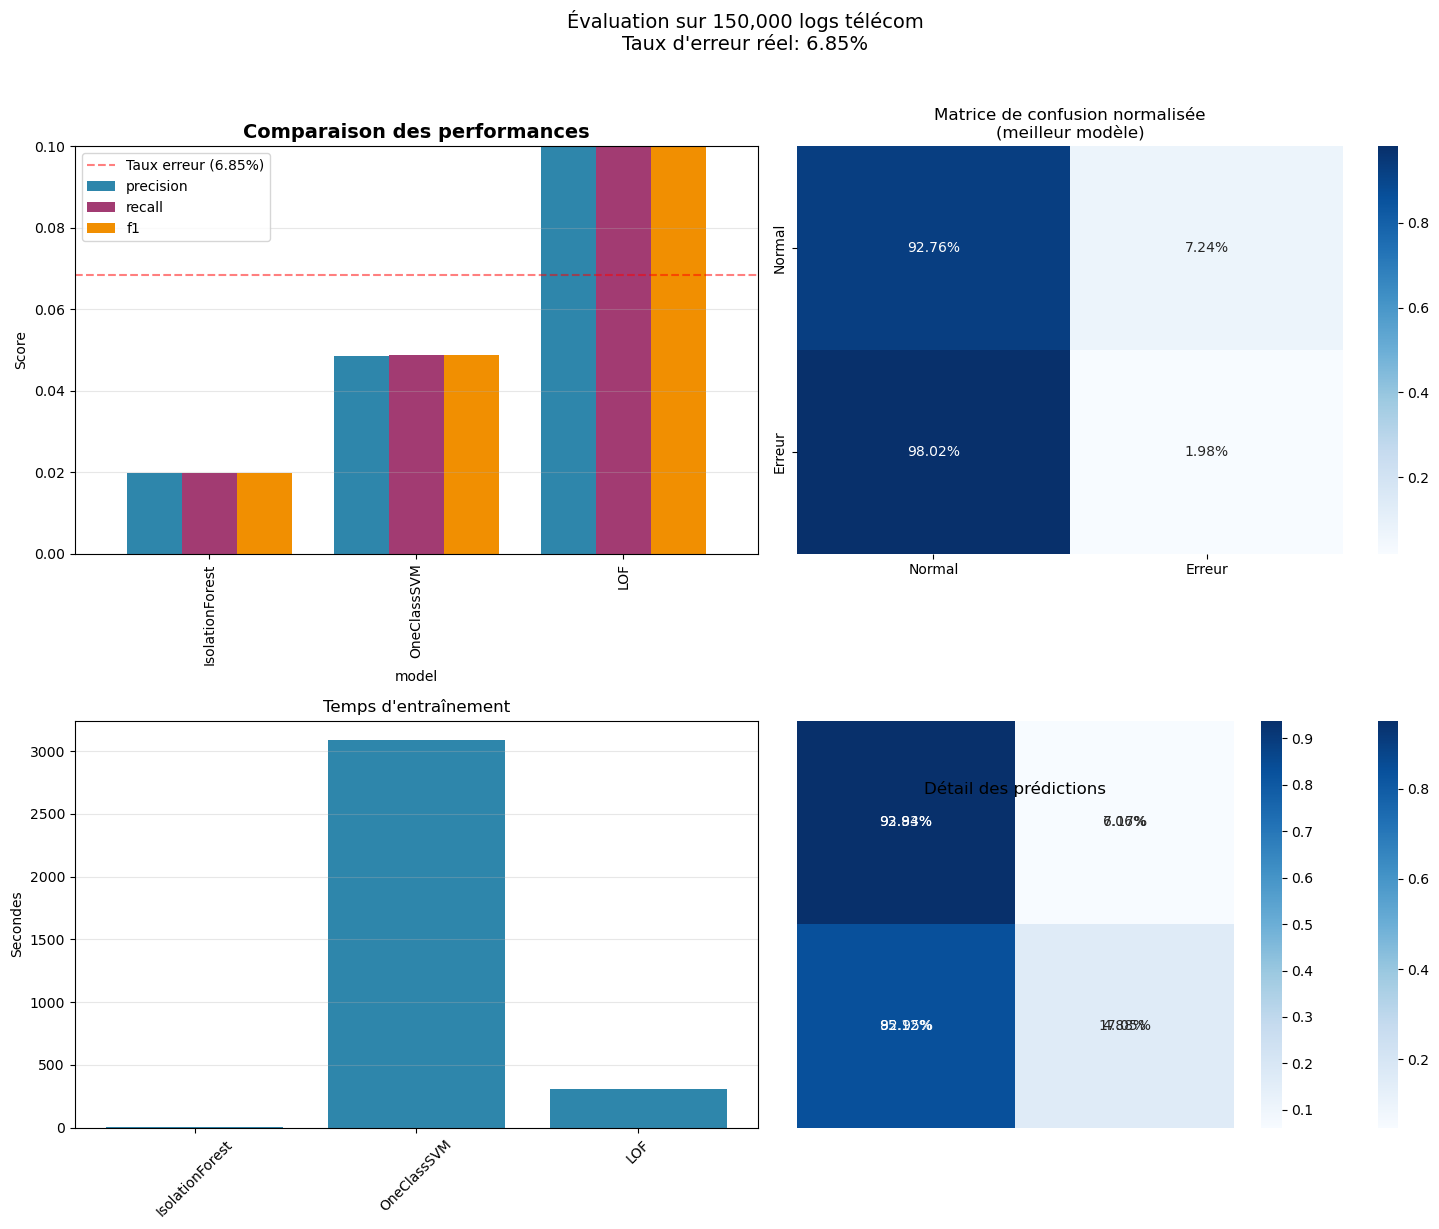

In [52]:
# Configuration du graphique
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Barres comparatives
ax1 = axes[0, 0]
results_df.set_index("model")[['precision', 'recall', 'f1']].plot(
    kind="bar", ax=ax1, width=0.8, 
    color=['#2E86AB', '#A23B72', '#F18F01']
)
ax1.set_title("Comparaison des performances", fontsize=14, fontweight='bold')
ax1.set_ylabel("Score")
ax1.set_ylim(0, 0.1)
ax1.axhline(y=error_rate, color='red', linestyle='--', alpha=0.5, 
            label=f'Taux erreur ({error_rate:.2%})')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# 2. Matrices de confusion
ax2 = axes[0, 1]
for i, (name, cm) in enumerate(conf_matrices.items()):
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', 
                xticklabels=['Normal', 'Erreur'],
                yticklabels=['Normal', 'Erreur'],
                ax=ax2 if i == 0 else None)
ax2.set_title("Matrice de confusion normalisée\n(meilleur modèle)")

# 3. Temps d'entraînement
ax3 = axes[1, 0]
ax3.bar(results_df['model'], results_df['train_time'], color='#2E86AB')
ax3.set_title("Temps d'entraînement")
ax3.set_ylabel("Secondes")
ax3.tick_params(axis='x', rotation=45)
ax3.grid(axis='y', alpha=0.3)

# 4. Détails des erreurs
ax4 = axes[1, 1]
ax4.axis('off')
table_data = []
for name, cm in conf_matrices.items():
    table_data.append([
        name,
        f"{cm[0,0]:,}",  # TN
        f"{cm[0,1]:,}",  # FP
        f"{cm[1,0]:,}",  # FN
        f"{cm[1,1]:,}"   # TP
    ])

table = ax4.table(cellText=table_data, 
                  colLabels=['Modèle', 'TN', 'FP', 'FN', 'TP'],
                  cellLoc='center', loc='center',
                  colWidths=[0.2, 0.15, 0.15, 0.15, 0.15])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)
ax4.set_title("Détail des prédictions", y=0.8)

plt.suptitle(f"Évaluation sur {len(X_test):,} logs télécom\nTaux d'erreur réel: {error_rate:.2%}", 
             fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [53]:
# Analyser pourquoi certaines erreurs sont détectées et d'autres non
print("\n🔍 ANALYSE DES CARACTÉRISTIQUES DISCRIMINANTES")

# Prendre le meilleur modèle
best_model_name = best_f1['model']
best_model = models[best_model_name]

# Prédictions complètes
preds_all = best_model.predict(X_test)
preds_all = (preds_all == -1).astype(int)

# Séparer les cas
tp = X_test[(y_test == 1) & (preds_all == 1)]  # Vrais positifs (erreurs détectées)
fn = X_test[(y_test == 1) & (preds_all == 0)]  # Faux négatifs (erreurs manquées)
fp = X_test[(y_test == 0) & (preds_all == 1)]  # Faux positifs (fausses alertes)
tn = X_test[(y_test == 0) & (preds_all == 0)]  # Vrais négatifs

print(f"\n📊 Distribution:")
print(f"  • Erreurs détectées (TP): {len(tp)}")
print(f"  • Erreurs manquées (FN): {len(fn)}")
print(f"  • Fausses alertes (FP): {len(fp)}")

# Analyser les caractéristiques
feature_names = feature_cols + ['hour_sin', 'hour_cos', 'day_sin', 'month_sin', 
                                'hour_day_ratio', 'message_density']

if len(tp) > 0 and len(fn) > 0:
    tp_mean = tp.mean(axis=0)
    fn_mean = fn.mean(axis=0)
    
    print("\n📈 Caractéristiques des erreurs détectées vs manquées:")
    print("-" * 60)
    for i, name in enumerate(feature_names[:10]):  # Top 10 features
        diff = tp_mean[i] - fn_mean[i]
        print(f"{name:20s}: Détectées={tp_mean[i]:8.2f} | Manquées={fn_mean[i]:8.2f} | Différence={diff:8.2f}")


🔍 ANALYSE DES CARACTÉRISTIQUES DISCRIMINANTES

📊 Distribution:
  • Erreurs détectées (TP): 1753
  • Erreurs manquées (FN): 8526
  • Fausses alertes (FP): 8618

📈 Caractéristiques des erreurs détectées vs manquées:
------------------------------------------------------------
hour                : Détectées=   -0.61 | Manquées=   -0.06 | Différence=   -0.55
day                 : Détectées=   -0.70 | Manquées=   -0.43 | Différence=   -0.27
month               : Détectées=   -0.13 | Manquées=   -0.00 | Différence=   -0.12
weekday             : Détectées=    0.08 | Manquées=    0.28 | Différence=   -0.21
message_length      : Détectées=   -0.31 | Manquées=   -0.34 | Différence=    0.03
hour_sin            : Détectées=    0.67 | Manquées=    0.06 | Différence=    0.61
hour_cos            : Détectées=    0.65 | Manquées=    0.41 | Différence=    0.24
day_sin             : Détectées=    0.82 | Manquées=    0.57 | Différence=    0.24
month_sin           : Détectées=   -0.14 | Manquées=   -0.26